**ESOPHAGEAL CANCER CLASSIFICATION USING LOGISTIC REGRESSION FOR WLI IMAGES**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression  # Import Logistic Regression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

In [ ]:
# Constants
BATCH_SIZE = 32
IMAGE_SIZE = 640
CHANNELS = 3

In [ ]:
import tensorflow as tf
import numpy as np

# Define the paths
train_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/train'
val_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/val'
test_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/test'

# Function to load and flatten the dataset
def load_and_flatten_data(directory, image_size=(224, 224), batch_size=32):
    # Load images from the directory
    dataset = tf.keras.preprocessing.image_dataset_from_directory(
        directory,
        image_size=image_size,
        batch_size=batch_size,
        shuffle=True
    )

    # Flatten the images and extract labels
    flat_data = []
    target_data = []
    for image_batch, labels_batch in dataset:
        for img, label in zip(image_batch, labels_batch):
            img_array = img.numpy().astype('uint8')  # Convert image to NumPy array
            img_flattened = img_array.flatten()      # Flatten the image
            flat_data.append(img_flattened)          # Append flattened image to the list
            target_data.append(label.numpy())        # Append label to the list

    return np.array(flat_data), np.array(target_data)

# Load and flatten each dataset
train_flat_data, train_labels = load_and_flatten_data(train_dir)
val_flat_data, val_labels = load_and_flatten_data(val_dir)
test_flat_data, test_labels = load_and_flatten_data(test_dir)

# Now you can use these flattened datasets for logistic regression


Found 751 files belonging to 3 classes.
Found 214 files belonging to 3 classes.
Found 109 files belonging to 3 classes.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Assign the flattened data to X and y variables for clarity
X_train, y_train = train_flat_data, train_labels
X_val, y_val = val_flat_data, val_labels
X_test, y_test = test_flat_data, test_labels

# Initialize the Logistic Regression model
logistic_model = LogisticRegression(max_iter=1000)  # Increase max_iter if convergence issues arise

# Train the model on the training data
logistic_model.fit(X_train, y_train)

# Evaluate the model on the validation data
y_val_pred = logistic_model.predict(X_val)
val_accuracy = accuracy_score(y_val, y_val_pred)
print(f'Validation Accuracy: {val_accuracy:.2f}')

# Evaluate the model on the test data
y_test_pred = logistic_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f'Test Accuracy: {test_accuracy:.2f}')

# Generate a classification report
print("\nClassification Report on Test Data:")
print(classification_report(y_test, y_test_pred))

# Generate a confusion matrix
print("\nConfusion Matrix on Test Data:")
print(confusion_matrix(y_test, y_test_pred))


Validation Accuracy: 0.64
Test Accuracy: 0.71

Classification Report on Test Data:
              precision    recall  f1-score   support

           0       0.75      0.80      0.78        41
           1       0.65      0.76      0.70        34
           2       0.72      0.53      0.61        34

    accuracy                           0.71       109
   macro avg       0.71      0.70      0.70       109
weighted avg       0.71      0.71      0.70       109


Confusion Matrix on Test Data:
[[33  4  4]
 [ 5 26  3]
 [ 6 10 18]]


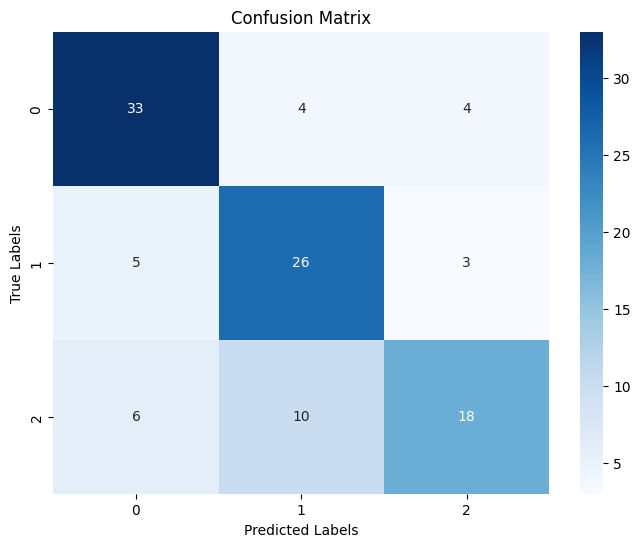

In [ ]:
# Assuming 'y_test' and 'y_test_pred' are defined from the previous code
cm = confusion_matrix(y_test, y_test_pred)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()


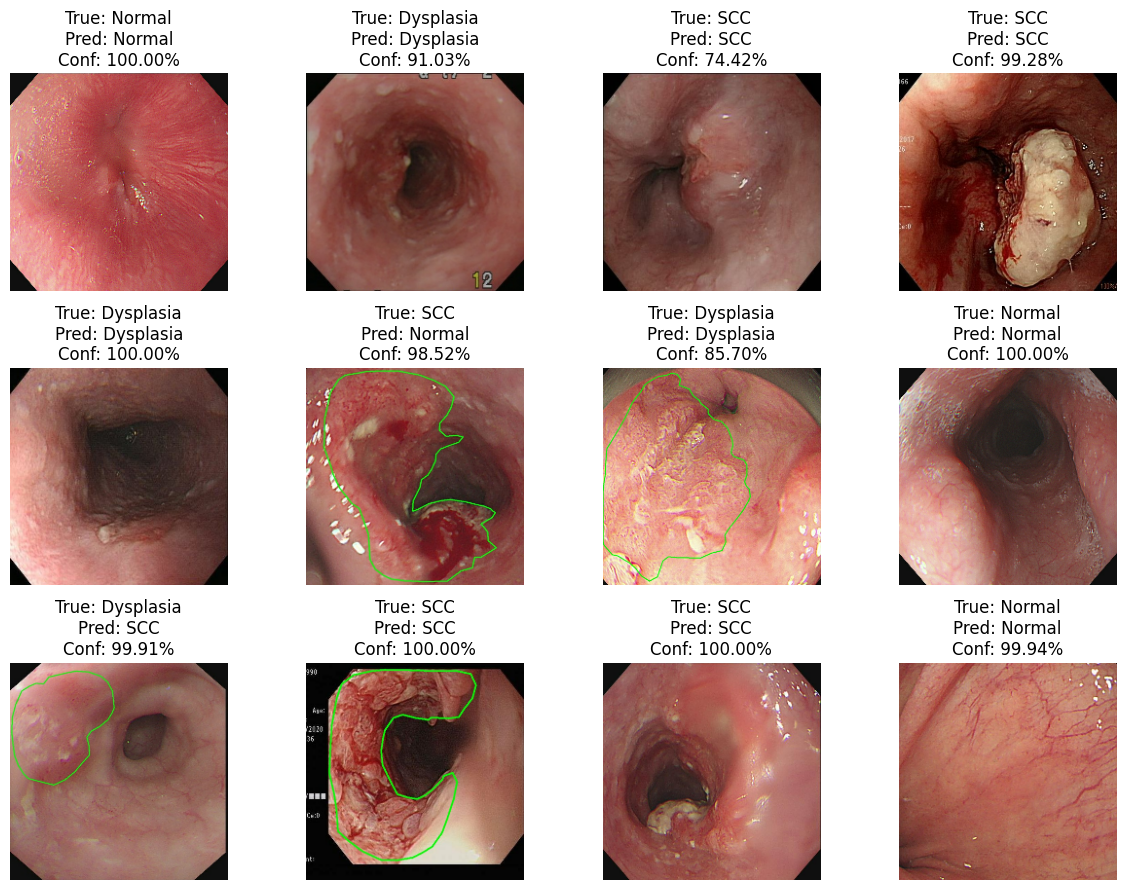

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming you have already loaded your test dataset and logistic model

# Make predictions and get prediction probabilities for the test dataset
y_test_pred = logistic_model.predict(X_test)  # Predicted labels
y_test_prob = logistic_model.predict_proba(X_test)  # Probabilities of each class

# Function to display images with predictions and confidence
def display_predictions(images, true_labels, predicted_labels, probabilities, class_names, num_images=12):
    plt.figure(figsize=(12, 9))  # Set the figure size
    for i in range(num_images):
        plt.subplot(3, 4, i + 1)  # 3x4 grid for displaying 12 images
        img = images[i].reshape(224, 224, 3)  # Reshape flat image back to 3D (adjust according to image size)
        plt.imshow(img)
        true_label = class_names[true_labels[i]]
        predicted_label = class_names[predicted_labels[i]]
        confidence = np.max(probabilities[i]) * 100  # Highest probability as confidence score
        plt.title(f"True: {true_label}\nPred: {predicted_label}\nConf: {confidence:.2f}%")
        plt.axis('off')  # Turn off axis

    plt.tight_layout()
    plt.show()

# Assuming you have your class names available
class_names = ['Dysplasia', 'Normal', 'SCC']  # Replace with your actual class names

# Display 12 predictions
display_predictions(test_flat_data, y_test, y_test_pred, y_test_prob, class_names, num_images=12) # Changed test_images to test_flat_data

In [ ]:
import joblib
# Save the trained Logistic Regression model to your working directory
joblib.dump(logistic_model, '/content/drive/MyDrive/new_dataset_EC/logistic fina/logistic_regression_model_WLI.pkl')


['/content/drive/MyDrive/new_dataset_EC/logistic fina/logistic_regression_model_WLI.pkl']

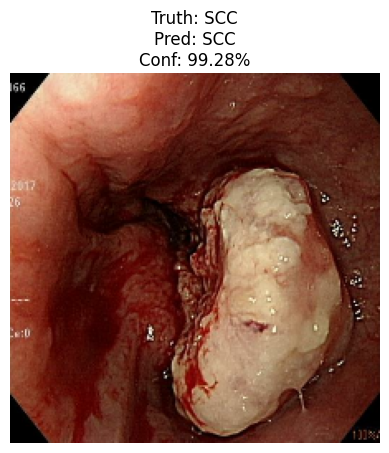

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
# Load the saved model
loaded_model = joblib.load('/content/drive/MyDrive/new_dataset_EC/logistic fina/logistic_regression_model_WLI.pkl')

# Select a single image from the test data
image_index = 3  # You can change this to select a different image
single_image = test_flat_data[image_index]
true_label = test_labels[image_index]

# Reshape the image
single_image_reshaped = single_image.reshape(1, -1)

# Make a prediction
predicted_label = loaded_model.predict(single_image_reshaped)[0]
predicted_prob = loaded_model.predict_proba(single_image_reshaped)[0]

# Get the predicted class name and confidence
predicted_class = class_names[predicted_label]
confidence = np.max(predicted_prob) * 100

# Display the image with prediction and true label
plt.figure()
plt.imshow(single_image.reshape(224, 224, 3))
plt.title(f"Truth: {class_names[true_label]}\nPred: {predicted_class}\nConf: {confidence:.2f}%")
plt.axis('off')
plt.show()


In [ ]:
# Save the model using joblib
import joblib
joblib.dump(logistic_model, '/content/drive/MyDrive/new_dataset_EC/logistic fina/logistic_regression_model_WLI.h5')

['/content/drive/MyDrive/new_dataset_EC/logistic fina/logistic_regression_model_WLI.h5']

In [ ]:
import os

/usr/local/lib/python3.10/dist-packages/sklearn/base.py:376: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.3.2 when using version 1.5.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


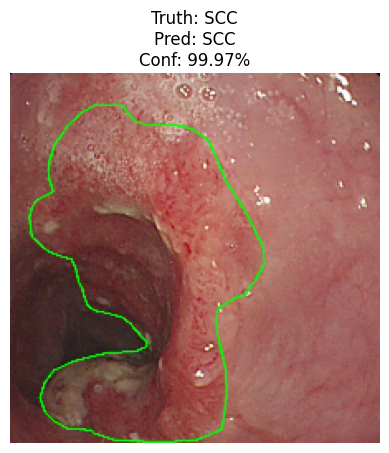

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import joblib
import os
# Load the saved model
loaded_model = joblib.load('/content/drive/MyDrive/new_dataset_EC/ec/EC/final/logistic_final/logistic_regression_model_WLI.pkl')

# Assuming you have your class names available
class_names = ['Dysplasia', 'Normal', 'SCC']  # Replace with your actual class names

# Get a test image from the SCC folder
test_scc_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/test/SCC'
image_path = os.path.join(test_scc_dir, os.listdir(test_scc_dir)[0]) # get first image
img = tf.keras.preprocessing.image.load_img(image_path, target_size=(224, 224))
img_array = tf.keras.preprocessing.image.img_to_array(img)
img_array = img_array.astype('uint8')
img_flattened = img_array.flatten()

# Reshape the image
single_image_reshaped = img_flattened.reshape(1, -1)


# Make a prediction
predicted_label = loaded_model.predict(single_image_reshaped)[0]
predicted_prob = loaded_model.predict_proba(single_image_reshaped)[0]

# Get the predicted class name and confidence
predicted_class = class_names[predicted_label]
confidence = np.max(predicted_prob) * 100

# Display the image with prediction and true label
plt.figure()
plt.imshow(img)
plt.title(f"Truth: SCC\nPred: {predicted_class}\nConf: {confidence:.2f}%")
plt.axis('off')
plt.show()


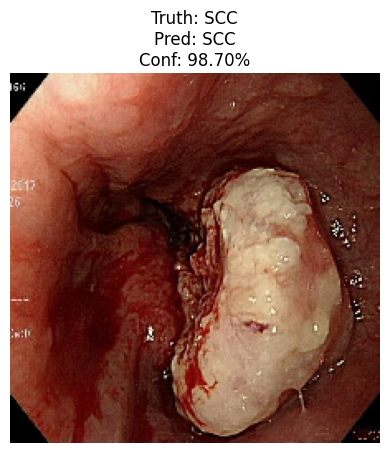

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
# Assuming you have your class names available
class_names = ['Dysplasia', 'Normal', 'SCC']  # Replace with your actual class names

# Get a test image from the SCC folder with specific name
test_scc_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/test/SCC'
image_name = 'CA090.jpg'  # Specify the desired image name
image_path = os.path.join(test_scc_dir, image_name)

# Check if the image exists
if os.path.exists(image_path):
    img = tf.keras.preprocessing.image.load_img(image_path, target_size=(224, 224))
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array = img_array.astype('uint8')
    img_flattened = img_array.flatten()

    # Reshape the image
    single_image_reshaped = img_flattened.reshape(1, -1)

    # Make a prediction
    predicted_label = loaded_model.predict(single_image_reshaped)[0]
    predicted_prob = loaded_model.predict_proba(single_image_reshaped)[0]

    # Get the predicted class name and confidence
    predicted_class = class_names[predicted_label]
    confidence = np.max(predicted_prob) * 100

    # Display the image with prediction and true label
    plt.figure()
    plt.imshow(img)
    plt.title(f"Truth: SCC\nPred: {predicted_class}\nConf: {confidence:.2f}%")
    plt.axis('off')
    plt.show()
else:
    print(f"Image '{image_name}' not found in the directory.")


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
# Assuming you have your class names available
class_names = ['Dysplasia', 'Normal', 'SCC']  # Replace with your actual class names

# Get a test image from the SCC folder
test_scc_dir = '/content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/test/SCC'

# Loop through all images in the SCC folder
for image_name in os.listdir(test_scc_dir):
    image_path = os.path.join(test_scc_dir, image_name)

    # Check if the file is an image (you can adjust the check as needed)
    if image_name.lower().endswith(('.png', '.jpg', '.jpeg')):
        try:
            img = tf.keras.preprocessing.image.load_img(image_path, target_size=(224, 224))
            img_array = tf.keras.preprocessing.image.img_to_array(img)
            img_array = img_array.astype('uint8')
            img_flattened = img_array.flatten()

            # Reshape the image
            single_image_reshaped = img_flattened.reshape(1, -1)

            # Make a prediction
            predicted_label = loaded_model.predict(single_image_reshaped)[0]
            predicted_prob = loaded_model.predict_proba(single_image_reshaped)[0]

            # Get the predicted class name and confidence
            predicted_class = class_names[predicted_label]
            confidence = np.max(predicted_prob) * 100

            # Display the image with prediction and true label
            plt.figure()
            plt.imshow(img)
            plt.title(f"Image: {image_name}\nTruth: SCC\nPred: {predicted_class}\nConf: {confidence:.2f}%")
            plt.axis('off')
            plt.show()

        except Exception as e:
            print(f"Error processing image '{image_name}': {e}")


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
!ls /content/drive/MyDrive/new_dataset_EC/Classification/Classification/WLI_split/test/SCC